In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import scvelo as scv

In [2]:
adata=sc.read_h5ad( "/home/julia/data/placodes/ANDYs_notebboks/Velocity_ANDY_23_09/Sub_8_13_4_UMAP.h5ad")

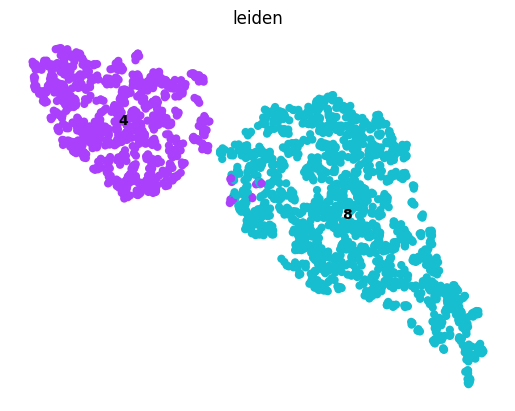

In [3]:
sc.pl.umap(adata, color=['leiden'], ncols=3, frameon=False, legend_loc="on data", size=140)

In [4]:
adata

AnnData object with n_obs × n_vars = 2564 × 32285
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020', 'leiden', 'leiden_1', 'leiden_parent', 'leiden_sub', 'leiden_sub4', 'leiden_sub2_1', 'leiden_sub3', 'leiden_sub3_1'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'day_colors', 'hvg', 'leiden', 'leiden_1', 'leiden_1_colors', 'leiden_colors', 'leiden_parent_colors', 'leiden_sub', 'leiden_sub2_1', 'leiden_sub2_1_colors', 'leiden_sub3', 'leiden_sub3_1', 'leiden_sub3_1_colors', 'leiden_sub3_colors', 'leiden_sub4', 'leiden_sub4_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'lognorm'
    obsp: 'connectivities', 'distan

In [5]:
# 1. Remove clusters 25, 24, 26
sub3= adata[
    ~adata.obs['leiden_sub'].astype(str).isin(["20", '13', '14'])
].copy()

sub3.obs["leiden_parent"] = sub3.obs["leiden_sub"].astype(str)

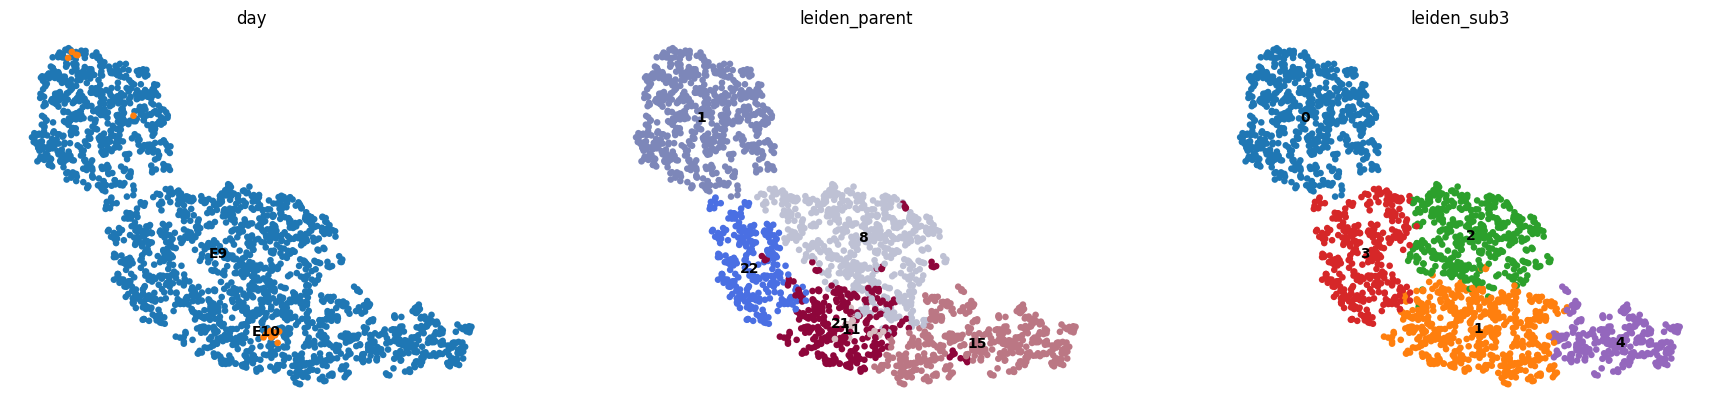

(2304, 32285)


In [6]:
sc.pp.neighbors(sub3, n_neighbors=70, n_pcs=40)
sc.tl.umap(sub3)
sc.tl.leiden(sub3, resolution=0.5, key_added="leiden_sub3")

sc.pl.umap(sub3, color=["day", "leiden_parent", "leiden_sub3"], frameon=False,
    legend_loc="on data",
    size=90
)

print(sub3.shape)

In [7]:
sc.tl.leiden(sub3, resolution=0.9, key_added="leiden_sub3_1")

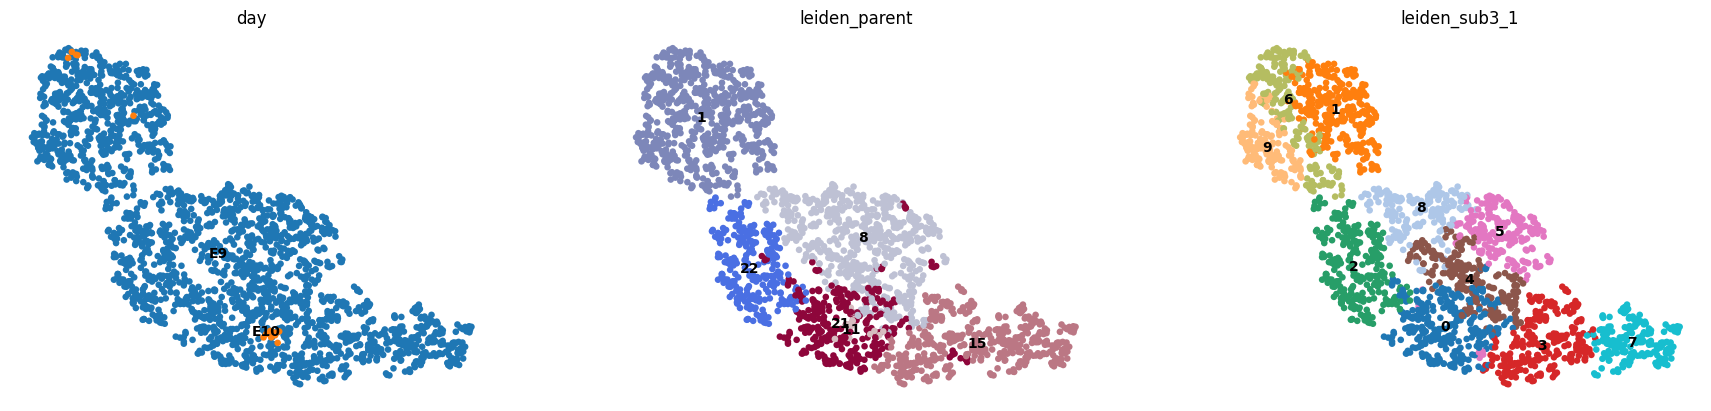

In [8]:
sc.pl.umap(
    sub3,
    color=["day", "leiden_parent", "leiden_sub3_1"],
    frameon=False,
    legend_loc="on data",
    size=90
)

In [9]:
sub3.write_h5ad("/home/julia/data/placodes/ANDYs_notebboks/Velocity_ANDY_23_09/Sub_8_13_4_UMAP_last.h5ad")

In [10]:
adata=sub3.copy()

In [11]:
# Full path to the merged loom file (the file, not just the folder)
merged_loom = "/home/julia/data/placodes/ANDY/loom_all/merged_E8_E11.loom"

# Open the loom as an AnnData object
# cache=True saves a fast-loading copy, so next time it opens in seconds
ldata = scv.read(merged_loom, cache=True)
ldata.var_names_make_unique()  # some gene symbols appear twice

# Quick look
print(ldata)
print("First barcodes:", list(ldata.obs_names[:3]))

AnnData object with n_obs × n_vars = 136387 × 32285
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    layers: 'ambiguous', 'matrix', 'spliced', 'unspliced'
First barcodes: ['E10_L003_mapped:AAAGGGCGTACAACGGx', 'E10_L003_mapped:AAAGGATGTGTTCCAAx', 'E10_L003_mapped:AAACGAAAGCTCTGTAx']


In [12]:
import re

# ---------------------------------------------------------------
# 1. Lookup table from adata: plate -> suffix  (e.g. "E9_L003" -> "adata1")
# ---------------------------------------------------------------
plate_to_suffix = (adata.obs[["plate", "sample_id"]]
                   .drop_duplicates()
                   .set_index("plate")["sample_id"]
                   .to_dict())
print(plate_to_suffix)   # should show 16 plates

{'E9_L003': 'adata1', 'E9_L004': 'adata2', 'E9_L005': 'adata3', 'E9_L006': 'adata4', 'E10_L003': 'adata5', 'E10_L004': 'adata6', 'E10_L005': 'adata7', 'E10_L006': 'adata8'}


In [13]:
# ---------------------------------------------------------------
# 2. Function that converts one velocyto name to adata style
#    "E10_L003_mapped:AAAGGGCGTACAACGGx" -> "AAAGGGCGTACAACGG-1-adata5"
# ---------------------------------------------------------------
def velocyto_to_adata(name):
    sample, barcode = name.split(":")                     # split prefix and barcode
    plate = sample.replace("_mapped", "")                 # "E10_L003"
    plate = re.sub(r"^(E\d+)_(\d+)$", r"\1_L\2", plate)   # fixes E9_003 -> E9_L003
    barcode = barcode.rstrip("x")                         # remove trailing "x"
    suffix = plate_to_suffix.get(plate, "UNMATCHED")      # look up "adataN"
    return f"{barcode}-1-{suffix}"

# ---------------------------------------------------------------
# 3. Keep the original names, then rename
# ---------------------------------------------------------------
ldata.obs["velocyto_name"] = ldata.obs_names
ldata.obs_names = [velocyto_to_adata(n) for n in ldata.obs_names]
print("New barcodes:", list(ldata.obs_names[:3]))

# ---------------------------------------------------------------
# 4. Check how well they match
# ---------------------------------------------------------------
n_shared = len(set(ldata.obs_names) & set(adata.obs_names))
n_unmatched = ldata.obs_names.str.endswith("UNMATCHED").sum()
print(f"Cells in adata:        {adata.n_obs}")
print(f"Cells matched:         {n_shared}")
print(f"Loom cells w/o plate:  {n_unmatched}")

New barcodes: ['AAAGGGCGTACAACGG-1-adata5', 'AAAGGATGTGTTCCAA-1-adata5', 'AAACGAAAGCTCTGTA-1-adata5']
Cells in adata:        2304
Cells matched:         2304
Loom cells w/o plate:  56493


In [14]:
import numpy as np

# 1. Which samples are unmatched? Should be only the four E8 plates
unmatched = ldata.obs_names.str.endswith("UNMATCHED")
print(ldata.obs.loc[unmatched, "velocyto_name"].str.split(":").str[0].value_counts())

# 2. Keep only matched cells (E9-E11)
ldata_e9_11 = ldata[np.array(~unmatched)].copy()

# 3. Names must be unique now
print("Unique names:", ldata_e9_11.obs_names.is_unique)
print("Matched cells:", len(set(ldata_e9_11.obs_names) & set(adata.obs_names)), "of", adata.n_obs)

E8_L004_mapped     8029
E8_L006_mapped     8026
E8_L003_mapped     8025
E8_L005_mapped     8020
E11_L004_mapped    6108
E11_L005_mapped    6108
E11_L003_mapped    6095
E11_L006_mapped    6082
Name: velocyto_name, dtype: int64
Unique names: True
Matched cells: 2304 of 2304


AnnData object with n_obs × n_vars = 2304 × 32285
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020', 'leiden', 'leiden_1', 'leiden_parent', 'leiden_sub', 'leiden_sub4', 'leiden_sub2_1', 'leiden_sub3', 'leiden_sub3_1', 'velocyto_name', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    uns: 'day_colors', 'hvg', 'leiden', 'leiden_1', 'leiden_1_colors', 'leiden_colors', 'leiden_sub', 'leiden_sub2_1', 'leiden_sub2_1_colors', 'leiden_sub3', 'leiden_sub3_1', 'leiden_sub4', 'leiden_sub4_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
 

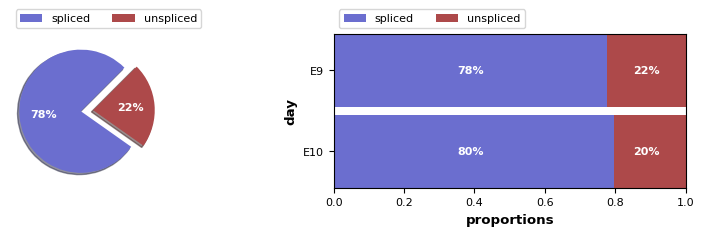

In [15]:

# 4. Merge
adata_vel = scv.utils.merge(adata, ldata_e9_11)
print(adata_vel)
scv.pl.proportions(adata_vel, groupby="day")

# Cell 2: preprocessing for velocity

In [16]:
# Normalize the spliced/unspliced layers and keep the top 2000 genes
scv.pp.filter_and_normalize(adata_vel, min_shared_counts=20, n_top_genes=2000)

# Smooth counts over each cell's neighbors (needed for velocity)
scv.pp.moments(adata_vel, n_pcs=30, n_neighbors=30)

Filtered out 24800 genes that are detected 20 counts (shared).
Normalized count data: spliced, unspliced.
Extracted 2000 highly variable genes.
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


# Cell 3: compute velocity

In [17]:
# Estimate velocity for each gene in each cell (stochastic model)
scv.tl.velocity(adata_vel)

# Build the velocity graph: the slowest step with ~125k cells, be patient
scv.tl.velocity_graph(adata_vel, n_jobs=6)   # n_jobs = CPU cores to use

computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 6/32 cores)


  0%|          | 0/2304 [00:00<?, ?cells/s]

    finished (0:00:07) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


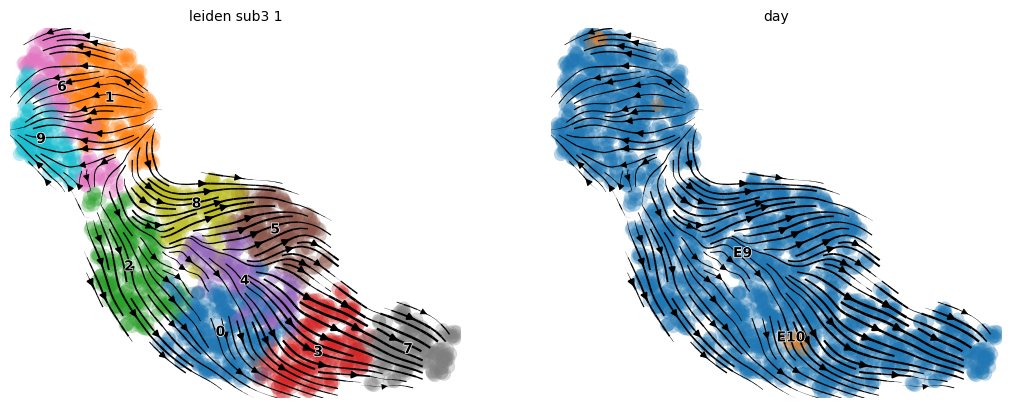

In [18]:
# Velocity arrows on your existing UMAP
scv.pl.velocity_embedding_stream(adata_vel, basis="umap", color=["leiden_sub3_1", "day"])

# Save so you never have to recompute
#adata_vel.write("/home/julia/data/placodes/ANDYs_notebbooks/h5ad/E8_E11_velocity.h5ad")

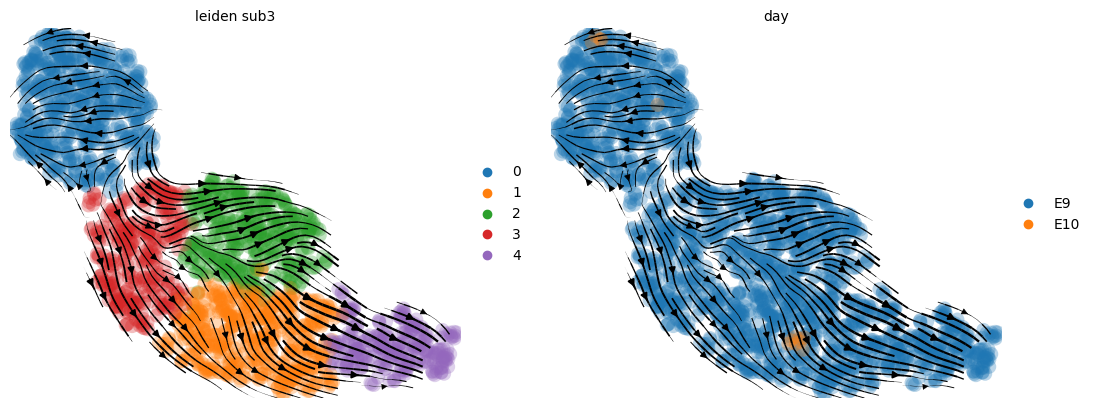

In [19]:
scv.pl.velocity_embedding_stream(adata_vel, basis="umap",  color=["leiden_sub3", "day"],
                                 legend_loc="right margin")

In [20]:
scv.tl.recover_dynamics(adata_vel, n_jobs=16)
scv.tl.velocity(adata_vel, mode="dynamical", vkey="velocity_dyn")
print("fit_t" in adata_vel.layers, "velocity_dyn" in adata_vel.layers)

recovering dynamics (using 16/32 cores)


  0%|          | 0/756 [00:00<?, ?gene/s]

    finished (0:00:28) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:02) --> added 
    'velocity_dyn', velocity vectors for each individual cell (adata.layers)
True True


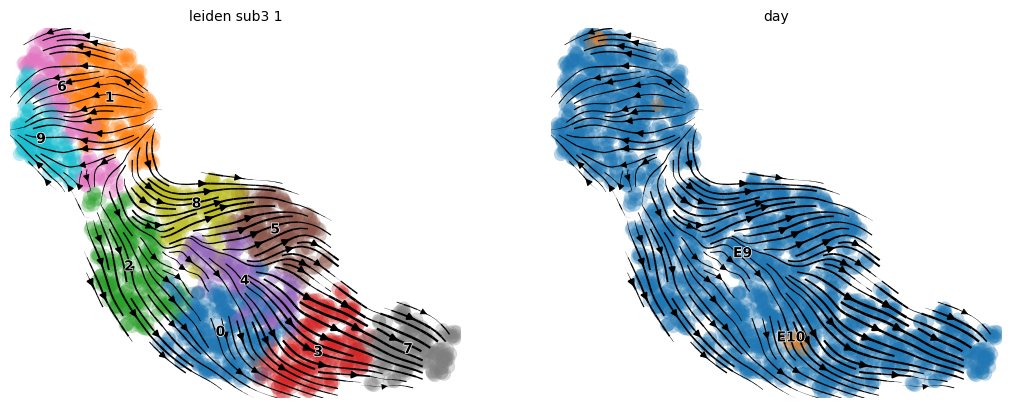

In [21]:
# Velocity arrows on your existing UMAP
scv.pl.velocity_embedding_stream(adata_vel, basis="umap", color=["leiden_sub3_1", "day"])

In [22]:
adata_vel.write_h5ad("/home/julia/data/placodes/ANDYs_notebboks/Velocity_ANDY_23_09/velocity_E9_11_cl_4_12.h5ad")